# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


/var/folders/h3/h_67p32s3r9gk7wsynfp604r0000gn/T/ipykernel_59256/3025898187.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['year'] = df['year'].apply(str)


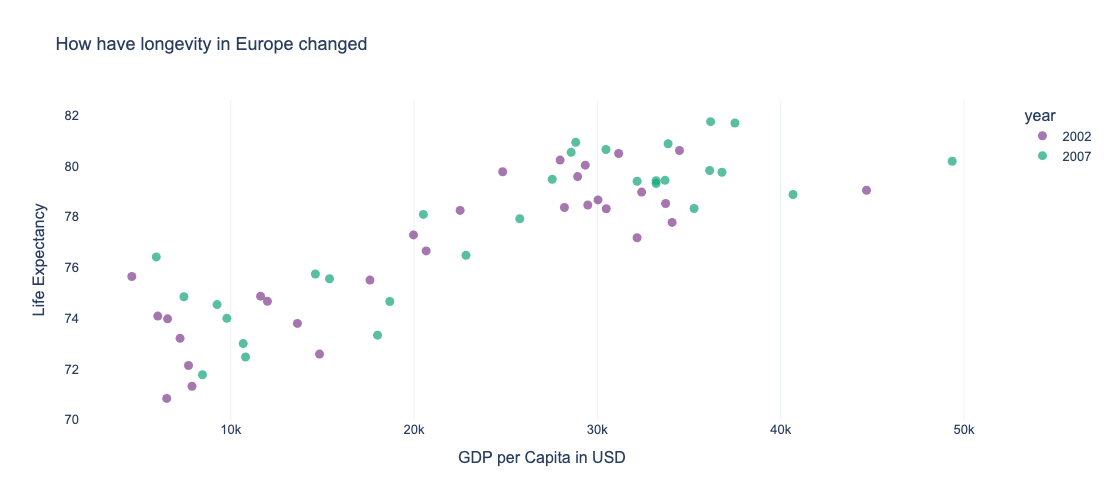

In [41]:
df1 = df.loc[(df['continent'] == 'Europe') & ((df['year'] == 2002) | (df['year'] == 2007))]
df1['year'] = df['year'].apply(str)

fig = px.scatter(
    data_frame=df1,
    x='gdpPercap',
    y='lifeExp',
    labels={'gdpPercap': 'GDP per Capita in USD',
            'lifeExp': 'Life Expectancy'},
    title='GDP vs Life Expectancy',
    height=500,
    color='year',
    template='plotly_white',
    color_discrete_sequence=px.colors.qualitative.Bold
)
fig.update_layout(
    title='How have longevity in Europe changed',
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=False),
    height=500
)

fig.update_traces(marker=dict(size=9, opacity=0.7))
fig.show()


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


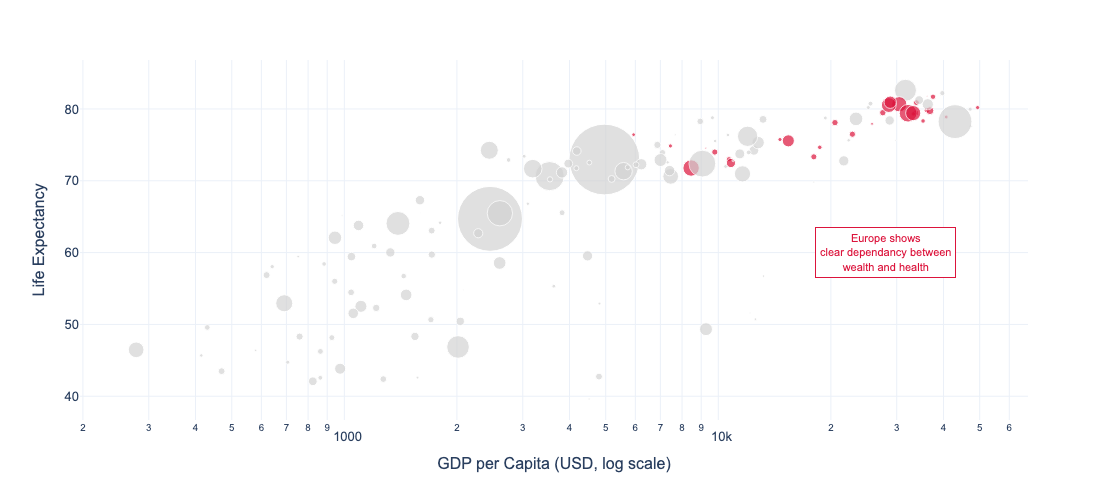

In [65]:
import math
df2 = df.loc[(df['year'] == 2007)]

highlight_continent = 'Europe'
colour_map = {c: ('crimson' if c == highlight_continent else 'lightgrey') for c in df['continent'].unique()}

fig = px.scatter(data_frame=df2, 
                 x='gdpPercap',
                 y='lifeExp',
                 size='pop',
                 size_max=50,
                 color='continent',
                 color_discrete_map=colour_map,                
                 hover_name='country',
                 hover_data={'continent':False},
                 log_x=True,                             # log scale: wealth is non-linear
                 labels={'gdpPercap': 'GDP per Capita (USD, log scale)', 'lifeExp': 'Life Expectancy'},
                 # color_discrete_sequence=px.colors.qualitative.Bold, 
                 template='plotly_white',
                 height=500
                )

fig.add_annotation(
    x=math.log10(28000), y=60,
    text='Europe shows<br>clear dependancy between<br>wealth and health',
    showarrow=False,
    font=dict(color='crimson', size=11, family='Arial'),
    bgcolor='white', bordercolor='crimson', borderwidth=1, borderpad=4
)

fig.update_layout(
    font=dict(family='Arial', size=13),
    showlegend=False,
    height=500
)

fig.show()